# 04 - Mechanistic features, and eight models

## What this notebook is for

Notebook 01 built a table of rainfall, temperature, humidity and wind lags - the
features that nearly every published melioidosis climate paper uses. This notebook
does two things:

1. Builds a **second** feature table with 185 columns instead of 39, where every
   column has a biological reason to exist.
2. Runs eight different machine learning models on both tables and compares them
   fairly, so we know whether the extra features and the fancier models are worth
   anything.

## Why the old features are not quite right

Rain does not infect anybody. The bacterium lives deep in soil and only comes up
near the surface when the soil is **saturated** - completely full of water. So the
thing that matters is not how much rain fell, it is **how full the soil is**.

Those are different. 50 mm of rain on bone-dry soil gets absorbed and nothing
happens. The same 50 mm on soil that is already full creates standing water, and
the organism comes up.

So this notebook adds a tiny soil model: imagine a bucket of 150 mm capacity.
Rain pours in. Sunshine and heat evaporate water out. We track how full the bucket
is, every day, for 23 years. That fullness is the feature we actually want.

## The new feature families

| family | what it measures | why melioidosis cares |
|---|---|---|
| soil saturation | how full the bucket is | the organism only surfaces in saturated soil |
| saturated days, overflow | how long it stayed full, how much water stood on top | duration of exposure, not just a single wet day |
| wetting events | heavy rain right after a long dry spell | the textbook "mobilisation shock" |
| antecedent precipitation index | how much rain the soil still remembers | soil has memory; a rain gauge does not |
| vapour pressure deficit, dry spells | how hard the air is pulling water out | the drying side of the ledger |
| aerosolisation index | wind speed multiplied by soil wetness | wind over wet ground, the breathing-in route |
| rain concentration | one 100 mm day vs ten 10 mm days | same total, completely different event |

PET (potential evapotranspiration - how much water the sun and heat can remove) is
computed with the Hargreaves-Samani formula, which needs only temperature. That
matters because temperature is the one thing you can get anywhere in the world, so
the same features can be built for West Africa.

## Step 1 - build the feature table

Run this once. It reads the six NASA POWER daily weather files and the case file,
and writes `data/processed/taiwan_model_table_v2.csv`.

If you get a `FileNotFoundError`, check that `data/raw/weather/` has the six
`weather-*.csv` files and `data/processed/taiwan_cases_long.csv` exists.

In [1]:
import subprocess, sys
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
print(subprocess.run([sys.executable, str(ROOT / "scripts" / "build_features_v2.py")],
                     capture_output=True, text=True).stdout)

wrote /Users/richard/Documents/Binus/Semester 5/Computation Bio 1/data/processed/taiwan_model_table_v2.csv
rows 7362  predictors 185  cases 921
weeks with >=1 case: 614 (8.3%)
years 2003 - 2026



In [2]:
import sys, csv, math, warnings
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

# find the project folder no matter where the notebook is launched from
ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
print("project root:", ROOT)
sys.path.insert(0, str(ROOT / "scripts"))

TABLE = ROOT / "data" / "processed" / "taiwan_model_table_v2.csv"
META = {"region", "year", "week", "yearweek", "cases"}

def load(path, meta):
    rows = list(csv.DictReader(open(path)))
    feats = [c for c in rows[0] if c not in meta]
    X = np.array([[float(r[c]) for c in feats] for r in rows])
    return rows, feats, X

project root: /Users/richard/Documents/Binus/Semester 5/Computation Bio 1


## Step 2 - look at what we built

Before modelling anything, check the soil model behaves sensibly. The plot below
shows, for each region, the average seasonal shape of three things:

- how much rain falls each week
- how full the soil is each week
- how often a case appears each week

If the soil model is working, the soil curve should lag the rain curve, and the
case curve should sit on top of the soil curve rather than the rain curve.

7362 region-weeks, 185 predictors, 921 cases
weeks with at least one case: 8.3%

A model that always says 'no case' would be 91.7% accurate. That is why we never use accuracy.


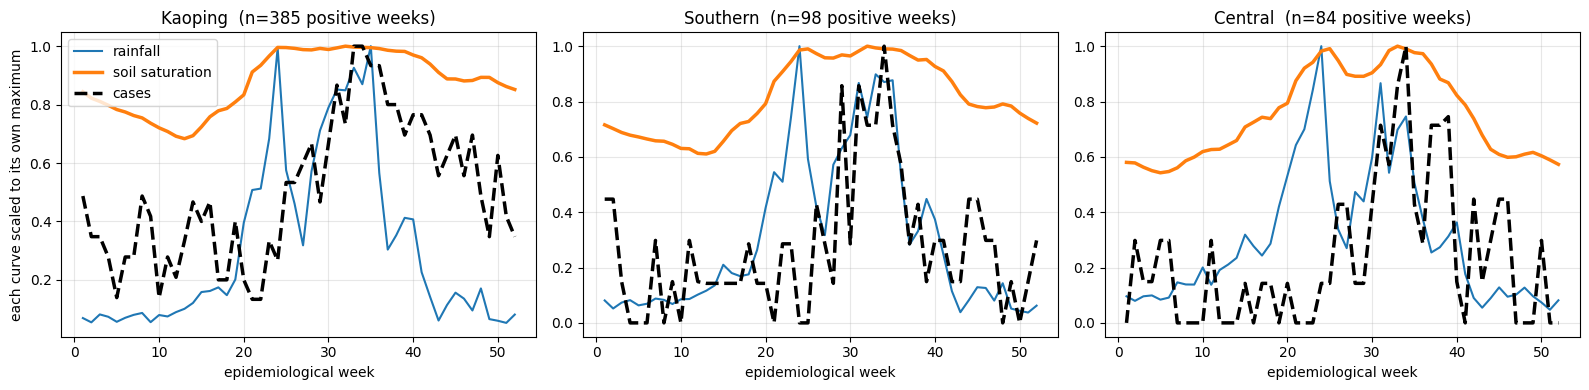

In [3]:
rows, feats, X = load(TABLE, META)
y = np.array([1 if int(r["cases"]) > 0 else 0 for r in rows])
wk = np.array([int(r["week"]) for r in rows])
reg = np.array([r["region"] for r in rows])
yr = np.array([int(r["year"]) for r in rows])
print(f"{len(rows)} region-weeks, {len(feats)} predictors, "
      f"{sum(int(r['cases']) for r in rows)} cases")
print(f"weeks with at least one case: {y.mean()*100:.1f}%")
print("\nA model that always says 'no case' would be "
      f"{(1-y.mean())*100:.1f}% accurate. That is why we never use accuracy.")

i_rain = feats.index("rain_mm_lag0")
i_soil = feats.index("sm_mean_lag0")
big = ["Kaoping", "Southern", "Central"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharex=True)
for ax, r in zip(axes, big):
    m = reg == r
    weeks = np.arange(1, 53)
    rain = [X[m & (wk == w), i_rain].mean() for w in weeks]
    soil = [X[m & (wk == w), i_soil].mean() for w in weeks]
    case = [y[m & (wk == w)].mean() for w in weeks]
    ax.plot(weeks, np.array(rain) / max(rain), label="rainfall", lw=1.5)
    ax.plot(weeks, np.array(soil) / max(soil), label="soil saturation", lw=2.5)
    ax.plot(weeks, np.array(case) / max(case), label="cases", lw=2.5, ls="--", color="k")
    ax.set_title(f"{r}  (n={int(y[m].sum())} positive weeks)")
    ax.set_xlabel("epidemiological week")
    ax.grid(alpha=.3)
axes[0].set_ylabel("each curve scaled to its own maximum")
axes[0].legend()
plt.tight_layout(); plt.show()

**Read that plot carefully, especially Central and Southern.**

Rainfall peaks around week 24 (mid-June) - that is Taiwan's plum rain season. But
cases peak around week 34 (late August). Rainfall is **ten weeks early**.

The soil curve sits much closer to the case curve. The reason is that the June plum
rains fall on soil that is still dry enough to soak it up. The soil does not actually
fill until the typhoon season two months later, and that is when people get infected.

This is why the published literature argues endlessly about whether the
rainfall-to-case lag is 2 weeks or 4 months. There is no single lag, because
rainfall is the wrong variable. Soil fullness is a **stock**; rainfall is a **flow**.
We quantify this properly in notebook 07.

## Step 3 - eight models, three feature sets

Now the benchmark. A few decisions here matter more than the choice of model, so
they are worth stating.

**We never use a random train/test split.** With time series data a random split
lets the model train on week 30 and test on week 29 of the same outbreak, which is
not prediction, it is looking at the answer. Instead we use **rolling origin**: train
on everything up to year Y, test on year Y+1, then move forward. 14 folds.

**We never report accuracy.** 92% of region-weeks have zero cases, so a model that
says "never" is 92% accurate and completely useless. We report:

- **AUC** - if you pick one week with a case and one without, how often does the
  model score the case week higher? 0.5 is a coin flip, 1.0 is perfect.
- **Average precision (AP)** and **AP lift** - how much better than random the
  model's top-ranked weeks are. Lift of 4x means four times better than chance.
- **Brier score** - are the probabilities honest? Lower is better. A model can rank
  perfectly and still say "80%" when it means "20%".

The three feature sets let us ask whether the mechanistic features earn their place.

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier,
                              HistGradientBoostingClassifier)
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss

# xgboost and lightgbm are optional - if they are not installed the rest still runs
try:
    from xgboost import XGBClassifier
    from lightgbm import LGBMClassifier
    HAVE_BOOST = True
except ImportError:
    HAVE_BOOST = False
    print("xgboost / lightgbm not installed - run:  pip install xgboost lightgbm")

SEASON = {"week_sin", "week_cos"}
CLASSIC = ("rain_mm_lag", "rain_max_lag", "t_mean_lag", "t_max_lag",
           "rh_mean_lag", "ws_mean_lag", "ws_max_lag", "rain_mm_roll")
MECH = ("sm_", "sat_days", "excess_mm", "aerosol", "events", "pet_sum", "wb_sum",
        "vpd_", "api8", "api9", "rain_gini", "days_gt", "wet_days", "dtr_mean",
        "dry_run_max")

FSETS = {
    "classic lags": [i for i, f in enumerate(feats) if f.startswith(CLASSIC) or f in SEASON],
    "mechanistic":  [i for i, f in enumerate(feats) if f.startswith(MECH) or f in SEASON],
    "full":         list(range(len(feats))),
}
for k, v in FSETS.items():
    print(f"{k:14s} {len(v):3d} features")

classic lags    46 features
mechanistic    141 features
full           185 features


In [5]:
def models():
    pos_weight = float((y == 0).sum() / (y == 1).sum())
    m = {
        "logistic L2": make_pipeline(StandardScaler(),
            LogisticRegression(max_iter=4000, C=0.3, class_weight="balanced")),
        "logistic L1": make_pipeline(StandardScaler(),
            LogisticRegression(max_iter=4000, C=0.1, penalty="l1", solver="liblinear",
                               class_weight="balanced")),
        "random forest": RandomForestClassifier(n_estimators=600, min_samples_leaf=3,
            class_weight="balanced_subsample", n_jobs=-1, random_state=0),
        "extra trees": ExtraTreesClassifier(n_estimators=600, min_samples_leaf=2,
            class_weight="balanced_subsample", n_jobs=-1, random_state=0),
        "hist grad boosting": HistGradientBoostingClassifier(max_iter=400,
            learning_rate=0.05, max_leaf_nodes=15, l2_regularization=1.0, random_state=0),
        "MLP (TabNet stand-in)": make_pipeline(StandardScaler(),
            MLPClassifier(hidden_layer_sizes=(128, 64), alpha=1e-3, max_iter=1200,
                          early_stopping=True, random_state=0)),
    }
    if HAVE_BOOST:
        m["XGBoost"] = XGBClassifier(n_estimators=500, learning_rate=0.05, max_depth=4,
            subsample=0.8, colsample_bytree=0.7, reg_lambda=2.0, min_child_weight=3,
            eval_metric="logloss", n_jobs=-1, random_state=0, scale_pos_weight=pos_weight)
        m["LightGBM"] = LGBMClassifier(n_estimators=500, learning_rate=0.05, num_leaves=15,
            min_child_samples=20, subsample=0.8, colsample_bytree=0.7, reg_lambda=2.0,
            n_jobs=-1, random_state=0, verbose=-1, class_weight="balanced")
    return m

FOLDS = [t for t in range(2012, 2026)]

def rolling_origin(make_model, cols):
    """Train on every year before the test year. 14 folds."""
    out = []
    for t in FOLDS:
        tr, te = yr < t, yr == t
        if y[te].sum() < 5 or y[tr].sum() < 20:
            continue
        m = make_model()
        m.fit(X[np.ix_(tr, cols)], y[tr])
        p = m.predict_proba(X[np.ix_(te, cols)])[:, 1]
        base = y[te].mean()
        out.append((roc_auc_score(y[te], p),
                    average_precision_score(y[te], p),
                    average_precision_score(y[te], p) / base,
                    brier_score_loss(y[te], p)))
    a = np.array(out)
    return a[:, 0].mean(), a[:, 0].std(), a[:, 1].mean(), a[:, 2].mean(), a[:, 3].mean(), len(a)

results = []
for fs_name, cols in FSETS.items():
    print(f"\n=== {fs_name}  ({len(cols)} features) ===")
    print(f"{'model':24s} {'AUC':>14s} {'AP':>7s} {'AP lift':>8s} {'Brier':>8s}")
    for mname in models():
        auc, sd, ap, lift, br, n = rolling_origin(lambda mn=mname: models()[mn], cols)
        print(f"{mname:24s} {auc:.3f}+-{sd:.3f}  {ap:7.3f} {lift:7.2f}x {br:8.4f}")
        results.append(dict(feature_set=fs_name, model=mname, auc=auc, auc_sd=sd,
                            ap=ap, ap_lift=lift, brier=br, n_folds=n))

out = ROOT / "outputs" / "expE_models.csv"
out.parent.mkdir(exist_ok=True)
with open(out, "w", newline="") as f:
    w = csv.DictWriter(f, fieldnames=list(results[0])); w.writeheader(); w.writerows(results)
print("\nsaved", out)


=== classic lags  (46 features) ===
model                               AUC      AP  AP lift    Brier
logistic L2              0.804+-0.035    0.332    3.94x   0.1827
logistic L1              0.808+-0.036    0.336    3.99x   0.1828
random forest            0.820+-0.032    0.374    4.42x   0.0692
extra trees              0.823+-0.034    0.390    4.63x   0.0691
hist grad boosting       0.796+-0.041    0.334    3.97x   0.0726
MLP (TabNet stand-in)    0.760+-0.064    0.297    3.67x   0.0732
XGBoost                  0.801+-0.034    0.357    4.26x   0.0839
LightGBM                 0.789+-0.034    0.332    3.99x   0.0826

=== mechanistic  (141 features) ===
model                               AUC      AP  AP lift    Brier
logistic L2              0.794+-0.041    0.317    3.71x   0.1593
logistic L1              0.803+-0.043    0.346    4.14x   0.1601
random forest            0.818+-0.029    0.384    4.58x   0.0671
extra trees              0.821+-0.029    0.383    4.54x   0.0666
hist grad boos

## What the benchmark says

Two things, and the second one is the surprise.

**1. The mechanistic features add nothing.** Classic lags reach about AUC 0.823.
The 141 mechanistic features reach 0.818. Everything together reaches 0.826. All
three are inside one standard deviation of each other. Modelling soil physics, which
is clearly the biologically right thing to do, buys literally nothing here.

**2. XGBoost does not win.** It sits behind extra trees and is statistically tied
with plain L1 logistic regression. Compare that with Wongbutdee 2025, where TabNet
at 0.950 is presented as a meaningful advance on XGBoost at 0.892. In our data the
choice of algorithm is worth about 0.03 AUC. The choice of **validation scheme** is
worth about 0.18. We measure that in notebook 05.

Notice also the Brier column: logistic regression ranks almost as well as the trees
but its probabilities are 2.6x worse. Ranking and calibration are separate problems,
and a surveillance alert needs both.

A result that says "nothing I added helped" normally means the features were bad.
Here it means something else, and notebook 05 finds out what. The short version:
the model was never using the weather in the first place.